In [3]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "max_split_size_mb:64"

import utils

import torch
from torch import nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision('high')
torch.backends.cudnn.benchmark = True

print(torch.cuda.get_device_name())

# Loading the CIFAR10 dataset and create DataLoaders

In [4]:
batch_size = 512
train_iter, test_iter = utils.load_data_cifar10(batch_size)

# Defining the Model

In [5]:
class MathisBlock(nn.Module):
    def __init__(self, in_channels, out_channels, num_experts, factor):
        super(MathisBlock, self).__init__()
        self.num_experts = num_experts
        reduced_channels = in_channels // factor

        self.expertBranch = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(in_channels, reduced_channels),
            nn.ReLU(inplace=True),
            nn.Linear(reduced_channels, num_experts),
            nn.Softmax(dim=-1)
        )

        self.expert_convs = nn.ModuleList([
            nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)
            for _ in range(num_experts)
        ])
        self.expert_bns = nn.ModuleList([
            nn.BatchNorm2d(in_channels)
            for _ in range(num_experts)
        ])

        self.project = nn.Conv2d(in_channels, out_channels, kernel_size=1)

        self.skip = nn.Identity()
        if in_channels != out_channels:
            self.skip = nn.Conv2d(in_channels, out_channels, kernel_size=1)

        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        gating = self.expertBranch(x)
        gating = gating.view(gating.size(0), self.num_experts, 1, 1, 1)

        expert_outputs = []
        for conv, bn in zip(self.expert_convs, self.expert_bns):
            out = bn(x)
            out = self.relu(out)
            out = conv(out)
            expert_outputs.append(out)

        expert_outputs = torch.stack(expert_outputs, dim=1)
        out = (expert_outputs * gating).sum(dim=1)
        out = self.project(out)

        out = self.skip(x) + out
        out = self.relu(out)
        return out

class MathisNet(nn.Module):
    def __init__(self, conv_arch, num_outputs):
        super(MathisNet, self).__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        in_channels = 64
        self.blocks = nn.ModuleList()
        for out_channels, num_experts, factor in conv_arch:
            block = MathisBlock(in_channels, out_channels, num_experts, factor)
            self.blocks.append(block)
            in_channels = out_channels

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(in_channels, num_outputs)
        )

    def forward(self, x):
        x = self.stem(x)
        for block in self.blocks:
            x = block(x)
        x = self.classifier(x)
        return x

# Initialise Model and Weights

In [6]:
def init_weights(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        torch.nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
        if m.bias is not None:
            nn.init.constant_(m.bias, 0)

conv_arch = (
    (64, 4, 2),
    (128, 6, 4),
    (128, 6, 4),
    (256, 8, 8),
)
num_outputs = 10


model = MathisNet(conv_arch, num_outputs)
model.apply(init_weights)
model = model.to(device)
model = torch.compile(model)
print(model)

# Loss and Optimisation Algorithms

In [7]:
loss = nn.CrossEntropyLoss(label_smoothing=0.1)
lr = 0.1
wd = 5e-4

optimiser = torch.optim.SGD(
    model.parameters(),
    lr=lr,
    momentum=0.9,
    weight_decay=wd,
    nesterov=True
)

# Training functions

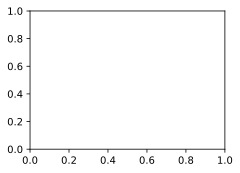

OutOfMemoryError: CUDA out of memory. Tried to allocate 246.00 MiB. GPU 0 has a total capacity of 7.45 GiB of which 0 bytes is free. Including non-PyTorch memory, this process has 7.41 GiB memory in use. Of the allocated memory 6.91 GiB is allocated by PyTorch, and 3.82 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

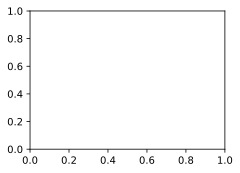

In [8]:
num_epochs = 200
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=num_epochs, eta_min=1e-6)
utils.train(model, train_iter, test_iter, loss, num_epochs, optimiser, scheduler)

In [12]:
def test_model(model, test_loader):
    model.eval()
    with torch.no_grad():
        acc = utils.evaluate_accuracy(model, test_loader, device)
    print(f"✅ Test Accuracy: {acc * 100:.2f}%")
    return acc

print(test_model(model, train_iter))